# 12 · The published benchmarks, and why the scores look low

So far this project has scored methods with micro F1 on samples. The papers on these test sets use other measures, on all
the test items. This notebook sets the earlier models beside the printed figures on those measures, using the same data
and splits, and measures why every score looks low.

**Pass marks, written before running.**
- Every model scored here has a ranking for every test item, or this notebook raises.
- On MultiEURLEX the measure and split must be the paper's: all 5,000 English test laws, or this notebook raises.
- If one way of averaging reproduces HumBERT's printed scores within 0.02 in every category, later notebooks compare on
  that average. If none does, the printed row stays the bar and the mismatch is stated.

Nothing is fine-tuned here except where stated. The averaging test uses the fine-tuned HumBERT from notebook 10's job, on
development items only.


In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image

from tiered_taxonomy import benchmarks as bm
from tiered_taxonomy import diagnosis as dg
from tiered_taxonomy import experiment as ex
from tiered_taxonomy import figures as fg
from tiered_taxonomy import new_technique as nt
from tiered_taxonomy import signals as sg
from tiered_taxonomy.config import FIGURES, data_root, load_config
from tiered_taxonomy.methods.trained import TrainedClassifier

root = data_root()
config = load_config()
seed = config["seed"]
words = config["text"]["input_words"]
humset = ex.load_humset(root)
eurlex = ex.load_eurlex(root)
results = {}

/Users/matthewharris/git/nvidia-autoontology-demo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The figures to beat, as printed

HumBERT is Tamagnone et al. (arXiv 2305.16756, table 5), whose table does not name its averaging. The HumSet paper is Fekih
et al. (arXiv 2210.04573), which says it reports macro averages. BERT on MultiEURLEX is Chalkidis et al. (arXiv 2109.00904),
mean R-Precision on the English chronological split.

In [2]:
printed = pd.DataFrame({"HumSet paper, XLM-R": bm.HUMSET_PAPER_XLM_R, "HumBERT, best": bm.HUMBERT_BEST})
printed.loc["Mean"] = printed.mean()
results["printed"] = {"humset": printed.round(3).to_dict(), "eurlex": bm.MULTI_EURLEX_BERT}
printed.round(3)

,"HumSet paper, XLM-R","HumBERT, best"
Sectors,0.730,0.780
Pillars 1D,0.530,0.700
Subpillars 1D,0.380,0.540
Pillars 2D,0.630,0.710
Subpillars 2D,0.400,0.510
Mean,0.534,0.648


## HumSet: the earlier models on the published measure

All 15,147 test excerpts. Macro F1 per category, with one threshold per label chosen on the whole development split.
Pillars are added to rankings from their strongest subpillar, because these models were trained on subpillars.

In [3]:
dev_items = nt.with_all_tiers(humset.dev)
test_items = nt.with_all_tiers(humset.test)
if len(test_items) != 15147:
    raise ValueError(f"expected all HumSet test excerpts, found {len(test_items)}")
dev_gold = [set(item.labels) for item in dev_items]
test_gold = [set(item.labels) for item in test_items]
rows = {}
for source in ("xr_transformer", "omikuji", "embedding_classifier", "knn", "label_search"):
    dev = nt.expand_sources({source: sg.load_signal(root, humset.name, source, "dev")})[source]
    test = nt.expand_sources({source: sg.load_signal(root, humset.name, source, "test")})[source]
    if any(item.id not in test for item in test_items):
        raise ValueError(f"{source} has no ranking for some HumSet test items")
    rows[source] = nt.humset_score(
        dev_gold,
        [dev.get(item.id, {}) for item in dev_items],
        test_gold,
        [test[item.id] for item in test_items],
        humset.taxonomy,
    )
table = pd.DataFrame(rows)
table.loc["Mean"] = table.mean()
results["humset_macro"] = table.round(3).to_dict()
table.round(3)

,xr_transformer,omikuji,embedding_classifier,knn,label_search
Sectors,0.731,0.685,0.674,0.656,0.440
Pillars 1D,0.519,0.454,0.462,0.437,0.171
Subpillars 1D,0.437,0.392,0.381,0.366,0.111
Pillars 2D,0.617,0.544,0.568,0.546,0.322
Subpillars 2D,0.444,0.376,0.392,0.384,0.142
Mean,0.550,0.490,0.496,0.478,0.237


## MultiEURLEX: the earlier models on the published measure

All 5,000 English test laws. Mean R-Precision on all labels, and at level 3 with each label rolled up through the tree.
Our level 3 has 545 labels against the paper's 567. A few labels in the raw data have no place in our tree (72 of 31,178 test
assignments), and are left out of gold labels and rankings; on development laws that moved a score by under 0.05.

In [4]:
if len(eurlex.test) != 5000:
    raise ValueError(f"expected all 5,000 test laws, found {len(eurlex.test)}")
gold = [set(item.labels) for item in eurlex.test]
rows = {}
for source in ("omikuji", "xr_transformer", "embedding_classifier", "knn", "label_search"):
    test = sg.load_signal(root, eurlex.name, source, "test")
    if any(item.id not in test for item in eurlex.test):
        raise ValueError(f"{source} has no ranking for some test laws")
    rows[source] = nt.eurlex_score(gold, [test[item.id] for item in eurlex.test], eurlex.taxonomy)
table = pd.DataFrame(rows)
table["BERT (printed)"] = pd.Series(bm.MULTI_EURLEX_BERT)
results["eurlex_mrp"] = table.round(2).to_dict()
table.round(2)

,omikuji,xr_transformer,embedding_classifier,knn,label_search,BERT (printed)
all,47.07,47.43,45.85,42.44,13.94,48.4
level_3,65.02,66.91,65.41,59.98,26.84,67.7


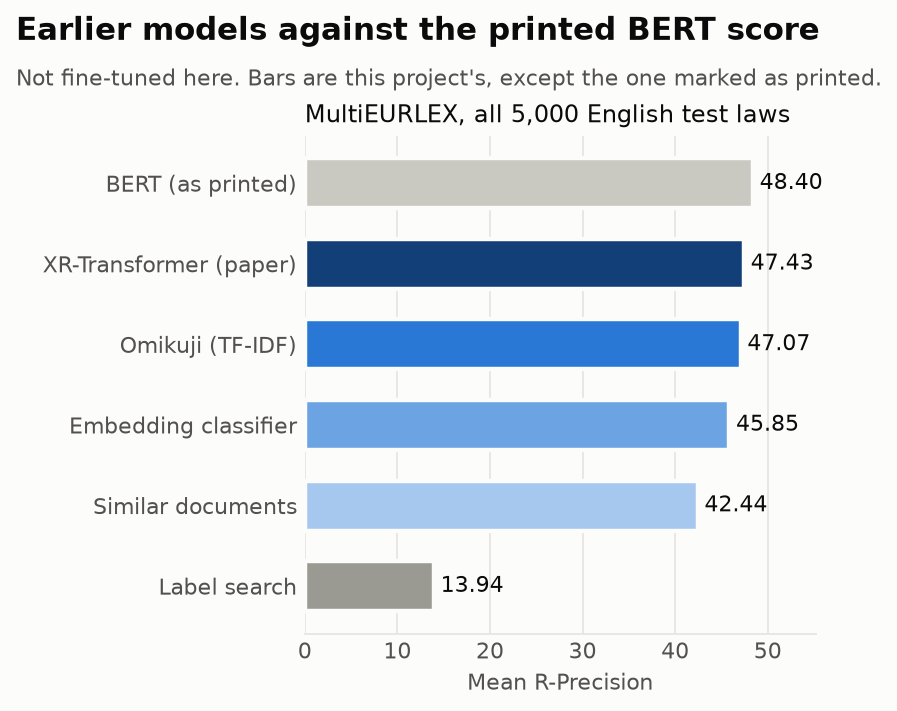

In [5]:
panel = {name: values["all"] for name, values in rows.items()} | {"bert_printed": bm.MULTI_EURLEX_BERT["all"]}
path = fg.method_bars(
    {"MultiEURLEX, all 5,000 English test laws": panel},
    "Mean R-Precision",
    "Earlier models against the printed BERT score",
    "Not fine-tuned here. Bars are this project's, except the one marked as printed.",
    FIGURES / "12_eurlex_published.png",
)
Image(str(path))

## What does HumBERT's table average?

Its table does not say. Here the fine-tuned HumBERT from notebook 10's job is scored every usual way, on development items
only, against the printed row. Thresholds come from 6,000 development items and scores from 4,000 others.

In [6]:
settings = config["new_technique"]["humset"]
order = np.random.default_rng(seed).permutation(len(humset.dev))
chosen = nt.with_all_tiers(
    [humset.dev[int(i)] for i in order[: settings["fit_items"] + settings["cut_items"]]]
)
fit, cut = chosen[: settings["fit_items"]], chosen[settings["fit_items"] :]
ranking = nt.expand_sources({"c": sg.load_signal(root, humset.name, "classifier", "dev")})["c"]
fit_gold = [set(item.labels) for item in fit]
cut_gold = [set(item.labels) for item in cut]
fit_rank = [ranking[item.id] for item in fit]
cut_rank = [ranking[item.id] for item in cut]
rows = {}
for category, labels in bm.humset_categories(humset.taxonomy).items():
    predicted = bm.apply_thresholds(cut_rank, bm.label_thresholds(fit_gold, fit_rank, labels))
    rows[category] = bm.other_averages(cut_gold, predicted, labels) | {"printed": bm.HUMBERT_BEST[category]}
averages = pd.DataFrame(rows).T
results["averages"] = averages.round(3).to_dict()
averages["closest gap"] = (
    (averages.drop(columns="printed").sub(averages["printed"], axis=0)).abs().min(axis=1)
)
matches = {
    name: bool(((averages[name] - averages["printed"]).abs() <= 0.02).all())
    for name in ("macro", "weighted", "micro", "sample")
}
results["average_reproduces_printed"] = matches
print("An average within 0.02 of the printed score in every category:", matches)
averages.round(3)

An average within 0.02 of the printed score in every category: {'macro': False, 'weighted': False, 'micro': False, 'sample': False}


,macro,weighted,micro,sample,printed,closest gap
Sectors,0.742,0.753,0.753,0.792,0.78,0.012
Pillars 1D,0.542,0.592,0.579,0.609,0.70,0.091
Subpillars 1D,0.453,0.536,0.455,0.524,0.54,0.004
Pillars 2D,0.644,0.678,0.677,0.729,0.71,0.019
Subpillars 2D,0.476,0.577,0.567,0.598,0.51,0.034


## Does newer data help on laws?

The chronological split tests on laws newer than any seen in training. The test: score Omikuji on the later half of the
development laws by date, with and without the earlier half in training. Then the same with a random division of those laws,
which is what a careless test of this would do. One run of one model, on development laws.

In [7]:
early, late = bm.split_by_date(eurlex.dev)
late_gold = [set(item.labels) for item in late]
train_only = sg.load_signal(root, eurlex.name, "omikuji", "dev")
with_newer = sg.load_signal(root, "eurlex_newer", "omikuji", "dev")
shuffled = np.random.default_rng(seed).permutation(len(eurlex.dev))
middle = len(shuffled) // 2
added = [eurlex.dev[int(i)] for i in shuffled[:middle]]
held = [eurlex.dev[int(i)] for i in shuffled[middle:]]
model = TrainedClassifier(config["trained"]["max_features"])
pool = [*eurlex.train, *added]
model.fit([ex.input_text(item, words) for item in pool], ex.gold_exact(pool))
random_after = model.rank([ex.input_text(item, words) for item in held], top_k=sg.RANK_DEPTH)
held_gold = [set(item.labels) for item in held]
drift = {
    "by date, training laws only": bm.mean_r_precision(late_gold, [train_only[item.id] for item in late]),
    "by date, with earlier development laws": bm.mean_r_precision(
        late_gold, [with_newer[item.id] for item in late]
    ),
    "at random, training laws only": bm.mean_r_precision(held_gold, [train_only[item.id] for item in held]),
    "at random, with half of development laws": bm.mean_r_precision(held_gold, random_after),
}
results["drift"] = {name: round(value, 2) for name, value in drift.items()}
results["drift"]

2026-11-10T01:01:03.672Z INFO  [omikuji::data] Loading data from /var/folders/9b/g2cxr52j3gz6bg6tpjjscd5w0000gn/T/tmp37xl75cu/train.txt
2026-11-10T01:01:03.817Z INFO  [omikuji::data] Parsing data


2026-11-10T01:01:04.387Z INFO  [omikuji::data] Loaded 57500 examples; it took 0.71s
2026-11-10T01:01:04.436Z INFO  [omikuji::model::train] Training model with hyper-parameters HyperParam { n_trees: 3, min_branch_size: 100, max_depth: 20, centroid_threshold: 0.0, collapse_every_n_layers: 0, linear: HyperParam { loss_type: Hinge, eps: 0.1, c: 1.0, weight_threshold: 0.1, max_iter: 20 }, cluster: HyperParam { k: 2, balanced: true, eps: 0.0001, min_size: 2 }, tree_structure_only: false, train_trees_1_by_1: false }
2026-11-10T01:01:04.437Z INFO  [omikuji::model::train] Initializing tree trainer
2026-11-10T01:01:04.517Z INFO  [omikuji::model::train] Computing label centroids


2026-11-10T01:01:11.252Z INFO  [omikuji::model::train] Start training forest


2 / 12929 [>-----------------------------------------------] 0.02 % 0.69/s 312m 

69 / 12937 [>----------------------------------------------] 0.53 % 20.30/s 11m 

71 / 12937 [>----------------------------------------------] 0.55 % 19.51/s 11m 

... (204 outputs left out)

12820 / 13293 [=========================================>-] 96.44 % 101.81/s 5s 

13293 / 13293 [=============================================] 100.00 % 104.77/s 

2026-11-10T01:03:18.170Z INFO  [omikuji::model::train] Model training complete; it took 133.73s


{'by date, training laws only': 52.7,
 'by date, with earlier development laws': 56.57,
 'at random, training laws only': 58.31,
 'at random, with half of development laws': 69.71}

## Why do the scores look low?

Four measures, on the best earlier model on each test set's sample from notebook 08. How strict is the scoring? How near are
the misses? How consistently did the original labellers treat the same text? How many right answers were ever on the table?

In [8]:
samples = config["samples"]
rng = np.random.default_rng(seed)
bands = [(0.99, 1.01), (0.95, 0.99), (0.9, 0.95), (0.8, 0.9)]
diagnosis = {}
for data, method in ((humset, "xr_transformer"), (eurlex, "omikuji")):
    if data is humset:
        sample = ex.sample_humset(data, samples["humset"]["per_language"], seed)
    else:
        settings = samples["eurlex"]
        sample = ex.sample_eurlex(
            data,
            settings["normal_documents"],
            settings["long_documents"],
            settings["long_threshold_words"],
            seed,
        )
    tuning = ex.pilot_subset(data.dev, config["trained"]["tuning_items"], seed)
    limits, thresholds = config["trained"]["cut_limits"], config["trained"]["cut_thresholds"]
    cut_rule, _ = sg.tuning_cut(tuning, sg.load_signal(root, data.name, method, "dev"), limits, thresholds)
    test_rankings = sg.load_signal(root, data.name, method, "test")
    gold = ex.gold_exact(sample)
    predicted = [cut_rule.apply(test_rankings[item.id]) for item in sample]
    query_positions = rng.choice(len(data.test), min(3000, len(data.test)), replace=False)
    test_vectors = sg.load_embeddings(root, data.name, "test")[query_positions]
    train_vectors = sg.load_embeddings(root, data.name, "train")
    full_gold = ex.gold_exact(data.test)
    diagnosis[data.name] = {
        "model": method,
        "gold labels per item": float(np.mean([len(labels) for labels in gold])),
        "predicted per item": float(np.mean([len(labels) for labels in predicted])),
        "items": dg.item_shares(gold, predicted),
        "errors": dg.error_shares(gold, predicted, data.taxonomy),
        "identical texts": dg.repeated_text_agreement([*data.train, *data.dev, *data.test]),
        "nearest training text": dg.nearest_text_agreement(
            test_vectors,
            [full_gold[int(i)] for i in query_positions],
            train_vectors,
            ex.gold_exact(data.train),
            bands,
        ),
    }
results["diagnosis"] = diagnosis
pd.json_normalize(diagnosis, sep=" · ").T.round(3)

,0
humset · model,xr_transformer
humset · gold labels per item,2.352667
humset · predicted per item,2.282667
humset · items · all right,0.262
humset · items · at least one right,0.856
humset · errors · wrong · unrelated,0.861461
humset · errors · wrong · sibling,0.138539
humset · errors · missed · unrelated,0.848765
humset · errors · missed · sibling,0.151235
humset · identical texts · pairs,27.0


In [9]:
ex.save_results("12_published_benchmarks", results)

PosixPath('/Users/matthewharris/git/nvidia-autoontology-demo/outputs/results/12_published_benchmarks.json')